# Global Health starts with the missing voices

**Objective:** Use observable contrasts to frame equitable questions without inventing vulnerability scores or intervention effects.

Original project lesson. All observations are real USGS Landsat / U.S. Census inputs, with source details in `data/manifest.json`. No health outcome is inferred.

A satellite can locate surface differences; it cannot identify community priorities, social protection, disability, occupation or access to care. Global Health asks how a decision is developed with affected people and how its burdens and benefits are distributed. The WHO framing is a starting point for that conversation, not a method for turning NDVI into a vulnerability index.

We compare geographic halves only as a descriptive sensitivity check. Neither half is a real neighborhood, an administrative decision area or a defined social group. A difference in surface conditions does not establish a difference in disease.

[Run this exact lesson in the browser Python Lab](https://jltobias.github.io/JupyterLite-OneHealth/lite/lab/index.html?path=08_equity_evidence_gaps.ipynb).

## Load the real bundled evidence

Run cells in order. In JupyterLite, the first run may download Python and Matplotlib and requires internet access. Wait for the kernel to finish. Files are in browser storage: use **File → Save and Export Notebook As** or right-click a file and **Download** to keep work outside this browser. Desktop execution uses the pinned build environment.

In [1]:
import sys, csv, json, math, statistics
from pathlib import Path
if sys.platform == "emscripten":
    import piplite
    await piplite.install("matplotlib")
import matplotlib.pyplot as plt
get_ipython().run_line_magic("matplotlib", "inline")
manifest = json.loads(Path("data/manifest.json").read_text())
with Path("data/pixels.csv").open() as f:
    rows = list(csv.DictReader(f))
text_fields = {"id"}
data = [{k: (v if k in text_fields else float(v) if v else None)
         for k, v in row.items()} for row in rows]
tracts = json.loads(Path("data/tracts.geojson").read_text())["features"]
def values(key, source=data):
    return [r[key] for r in source if r[key] is not None and math.isfinite(r[key])]
def avg(key, source=data):
    a = values(key, source)
    return statistics.mean(a) if a else None
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
print(manifest["scene_id"], manifest["satellite_datetime"])
print("Real satellite samples:", len(data), "| population reference:", manifest["population_date"])


LC09_L2SP_042035_20240830_02_T1 2024-08-30T18:33:53.353894Z
Real satellite samples: 6890 | population reference: 2020-04-01


## Inspect the calculation

The following code keeps source units and dates explicit. Edit assumptions only after recording what changes.

In [2]:
mid = (manifest["bbox"][0] + manifest["bbox"][2])/2
west = [r for r in data if r["lon"] < mid]
east = [r for r in data if r["lon"] >= mid]
for label, subset in [("West geometric half",west),("East geometric half",east)]:
    print(label, "samples",len(subset), "surface °C",round(avg("temperature_c",subset),2))
missing = ["Community priorities", "Air and indoor temperature", "Animal health", "Water chemistry", "Service access"]
print("Evidence absent from this package:", "; ".join(missing))

West geometric half samples 3445 surface °C 43.08
East geometric half samples 3445 surface °C 44.05
Evidence absent from this package: Community priorities; Air and indoor temperature; Animal health; Water chemistry; Service access


## Make a figure from the observations

The figure describes the selected real evidence. It does not establish personal exposure or a causal health effect.

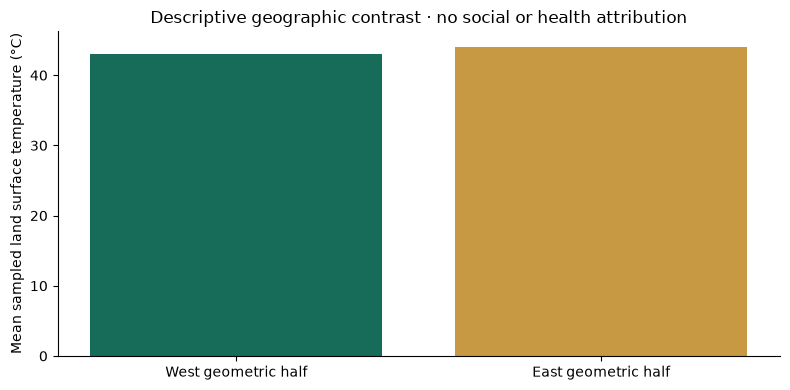

In [3]:
plt.bar(["West geometric half","East geometric half"], [avg("temperature_c",west),avg("temperature_c",east)], color=["#176c59","#c89943"])
plt.ylabel("Mean sampled land surface temperature (°C)")
plt.title("Descriptive geographic contrast · no social or health attribution")
plt.tight_layout(); plt.show()

## Interpret and extend

Draft a meeting agenda for community, veterinary, environmental and health-service partners. Name one question they could reject or redefine. Explain what evidence would be needed to evaluate an intervention rather than simulate its benefits.

## Sources and attribution

- [WHO, One Health](https://www.who.int/health-topics/one-health).
- [CDC, About One Health](https://www.cdc.gov/one-health/about/index.html).
- [USGS EROS, Landsat Collection 2 Level-2 science products; dataset DOI 10.5066/P9OGBGM6](https://www.usgs.gov/landsat-missions/landsat-collection-2-level-2-science-products).
- [U.S. Census Bureau, Census2020 TIGERweb Census Tracts layer 6 and POP100](https://tigerweb.geo.census.gov/arcgis/rest/services/Census2020/tigerWMS_Census2020/MapServer/6).

Data: USGS/NASA Landsat 8–9 Collection 2 Level-2, public domain; U.S. Census Bureau 2020 Census tracts and population, public domain. Accessed/acquired 7 November 2026. External readings are linked only; their prose, photographs, figures and code are not reproduced. Source organizations do not endorse this lesson.